# 003. Partial Pooling

## Simplified Overview

Partial pooling is a middle-ground strategy between treating every group (e.g., each customer, each software package) completely independently and forcing all groups to follow the same global pattern. It allows groups to have their own trends while also "borrowing strength" from the aggregate pattern—groups with more data anchor closer to their own observations, groups with sparse data move closer to the global average.

## Technical Overview

**Partial Pooling** (also called "shrinkage estimation" or "empirical Bayes") leverages hierarchical modeling to estimate group-level parameters by combining:

* **Local information**: Group-specific observed data
* **Global information**: Population-level prior distribution

The group estimate is a weighted average:
```
θ_group ≈ λ · θ_group_obs + (1 - λ) · θ_global_prior
```
where λ depends on group sample size and between-group variance.

## Detailed Explanation

### The Three Pooling Extremes

| Approach | Formula | Pros | Cons |
| :--- | :---: | :---: | :---: |
| No Pooling | θ_i = observed mean in group i | Unbiased for large samples; captures group-level variation | High variance; overfits small groups |
| Complete Pooling | θ_i = global mean for all i | Low variance; stable | Biased; ignores group differences |
| Partial Pooling | θ_i = λ·observed_i + (1-λ)·global | Bias-variance tradeoff; adaptive | Requires estimating hyperparameters |

### Mathematical Formulation

Standard hierarchical model:

```
Data level:          y_ij ~ N(μ_i, σ_within²)    [observation j in group i]
Group level:         μ_i ~ N(μ_global, σ_between²)  [group i parameter]
Hyperprior level:    μ_global ~ N(0, σ_prior²)    [population mean]
```

Posterior estimate for group i:

```
μ_i | data = [n_i/σ_within² · ȳ_i + μ_global/σ_between²] / [n_i/σ_within² + 1/σ_between²]
           = λ_i · ȳ_i + (1 - λ_i) · μ_global
```

where `λ_i = (n_i/σ_within²) / (n_i/σ_within² + 1/σ_between²)`

Key insight: `λ_i ∈ [0,1]` depends on:
* `n_i`: Group sample size (larger → `λ_i` closer to 1)
* `σ_within²`: Within-group noise (smaller → `λ_i` closer to 1)
* `σ_between²`: Between-group variance (larger → `λ_i` closer to 1)

### Use Cases
1. **Multi-site studies**: Estimate treatment effect per hospital/clinic while borrowing from aggregate
2. **Recommendation systems**: User-specific preferences constrained by population distribution
3. **Exploit prediction (EPSS context)**: Vulnerability exploitation risk per software package, constrained by global exploitation patterns
4. **Customer segmentation**: Group-level churn probability combining customer-specific history with cohort trends

## Python Libraries
| Library | Purpose |
| :--- | :---: |
| `pymc` | Probabilistic programming for hierarchical models |
| `arviz` | Bayesian inference and diagnostics |
| `statsmodels` | Mixed-effects models (`smf.mixedlm`) |
| `scikit-learn` | Baseline models |
| `scipy.stats` | Beta, Normal distributions for parameter estimation |

## References
* Efron, B., & Morris, C. (1977). "Stein's Estimation Rule and Its Competitors—An Empirical Bayes Approach." _Journal of the American Statistical Association_, **68**(341), 117-130.
* Gelman, A., et al. (2013). _Bayesian Data Analysis_ (3rd ed.). Chapman and Hall/CRC.
* Robinson, G. K. (1991). "That BLUP Is a Good Thing: The Estimation of Random Effects." _Statistical Science_, **6**(1), 15-32.

## Python Implementation Examples

### Imporation of Requisite Python Modules

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

### Example: Exploitation Risk Estimation per Software Package

In [3]:
# Simulate data: 20 software packages with varying exploitation rates
np.random.seed(42)
n_packages = 20
package_names = [f"Package_{i}" for i in range(n_packages)]

# True underlying exploitation rates (between-group variation)
true_exploit_rates = np.random.beta(2, 5, n_packages)  # Most packages have low rates

# Observe: different sample sizes per package (realistic)
n_obs = np.random.randint(10, 200, n_packages)

# Generate observed exploitation counts
observed_exploits = np.array([
    np.random.binomial(n, p) for n, p in zip(n_obs, true_exploit_rates)
])

# Observed exploitation rates (no pooling)
observed_rates = observed_exploits / n_obs

print("Sample Data (10 packages shown):")
df_data = pd.DataFrame({
    'Package': package_names[:10],
    'N_Observed': n_obs[:10],
    'N_Exploited': observed_exploits[:10],
    'Observed_Rate': observed_rates[:10]
})
print(df_data.to_string(index=False))

Sample Data (10 packages shown):
  Package  N_Observed  N_Exploited  Observed_Rate
Package_0         108           40       0.370370
Package_1         181           50       0.276243
Package_2         113           46       0.407080
Package_3          44            5       0.113636
Package_4         110           52       0.472727
Package_5         184           22       0.119565
Package_6         140           76       0.542857
Package_7          10            2       0.200000
Package_8          14            4       0.285714
Package_9         151           43       0.284768


In [4]:
# ============================================================================
# Approach 1: NO POOLING (naive per-package estimate)
# ============================================================================

no_pool_estimates = observed_rates.copy()
print(f"\nNo Pooling - Mean rate: {no_pool_estimates.mean():.4f}")


No Pooling - Mean rate: 0.2792


In [5]:
# ============================================================================
# Approach 2: COMPLETE POOLING (all packages same rate)
# ============================================================================

complete_pool_estimate = observed_exploits.sum() / n_obs.sum()
complete_pool_estimates = np.full(n_packages, complete_pool_estimate)
print(f"Complete Pooling - Rate: {complete_pool_estimate:.4f}")

Complete Pooling - Rate: 0.3023


In [ ]:
# ============================================================================
# Approach 3: PARTIAL POOLING (Bayesian hierarchical model)
# ============================================================================

In [6]:
# Step 1: Estimate global parameters via maximum likelihood
# Assume observed counts ~ Binomial(n_i, p_i), p_i ~ Beta(α, β)

# MLE for Beta parameters using method of moments
global_mean = observed_exploits.sum() / n_obs.sum()
global_variance = np.var(observed_rates)  # Sample variance of rates

# Reparameterize: Beta(α, β) with mean α/(α+β) and variance derived from α,β
# Using method of moments:
# E[p] = α/(α+β) = global_mean
# Var[p] = αβ/((α+β)²(α+β+1)) ≈ global_variance

# Simplified estimation:
alpha = global_mean * (global_mean * (1 - global_mean) / max(global_variance, 1e-4) - 1)
beta = (1 - global_mean) * (global_mean * (1 - global_mean) / max(global_variance, 1e-4) - 1)

alpha = max(alpha, 0.1)  # Ensure positive
beta = max(beta, 0.1)

print(f"\nPartial Pooling (Empirical Bayes):")
print(f"  Estimated global Beta parameters: α={alpha:.4f}, β={beta:.4f}")


Partial Pooling (Empirical Bayes):
  Estimated global Beta parameters: α=2.9836, β=6.8851


In [7]:
# Step 2: Posterior estimate for each package
# Posterior: Beta(α + exploits_i, β + non_exploits_i)
partial_pool_estimates = np.zeros(n_packages)
posterior_std = np.zeros(n_packages)

for i in range(n_packages):
    alpha_posterior = alpha + observed_exploits[i]
    beta_posterior = beta + (n_obs[i] - observed_exploits[i])
    
    # Posterior mean
    partial_pool_estimates[i] = alpha_posterior / (alpha_posterior + beta_posterior)
    
    # Posterior std
    var_posterior = (alpha_posterior * beta_posterior) / \
                    ((alpha_posterior + beta_posterior)**2 * (alpha_posterior + beta_posterior + 1))
    posterior_std[i] = np.sqrt(var_posterior)

print(f"  Mean pooled estimate: {partial_pool_estimates.mean():.4f}")

  Mean pooled estimate: 0.2868


In [8]:
# ============================================================================
# Step 3: Compute shrinkage weights λ_i
# ============================================================================

shrinkage_weights = n_obs / (n_obs + (1 - global_mean) / global_mean)
print(f"\nShrinkage weights (first 5 packages):")
for i in range(5):
    print(f"  Package_{i}: λ={shrinkage_weights[i]:.4f} (n={n_obs[i]})")


Shrinkage weights (first 5 packages):
  Package_0: λ=0.9791 (n=108)
  Package_1: λ=0.9874 (n=181)
  Package_2: λ=0.9800 (n=113)
  Package_3: λ=0.9502 (n=44)
  Package_4: λ=0.9795 (n=110)



Plot saved (conceptual)


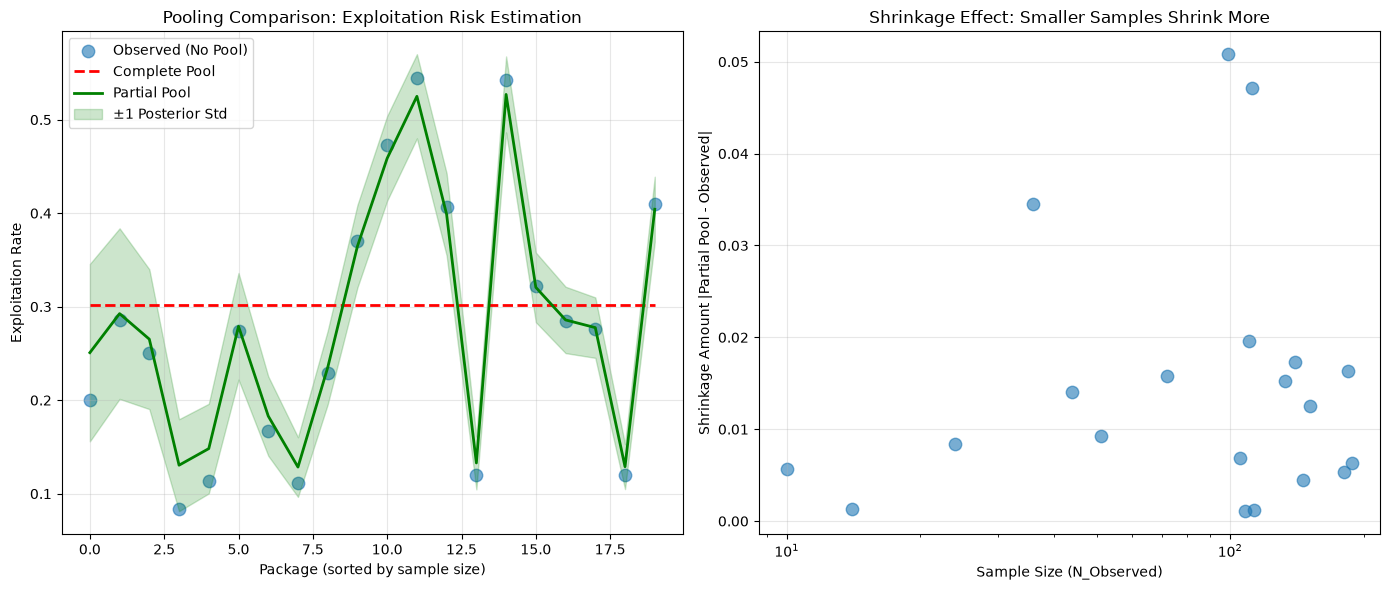

In [9]:
# ============================================================================
# Comparison: Visualization
# ============================================================================

results_df = pd.DataFrame({
    'Package': package_names,
    'N_Observed': n_obs,
    'Observed_Rate': observed_rates,
    'No_Pool': no_pool_estimates,
    'Complete_Pool': complete_pool_estimates,
    'Partial_Pool': partial_pool_estimates,
    'Posterior_Std': posterior_std
})

# Sort by sample size for visualization
results_df_sorted = results_df.sort_values('N_Observed')

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Comparison of estimates vs. observed rates
ax = axes[0]
x_pos = np.arange(len(results_df_sorted))
ax.scatter(x_pos, results_df_sorted['Observed_Rate'], label='Observed (No Pool)', alpha=0.6, s=80)
ax.plot(x_pos, results_df_sorted['Complete_Pool'], 'r--', label='Complete Pool', linewidth=2)
ax.plot(x_pos, results_df_sorted['Partial_Pool'], 'g-', label='Partial Pool', linewidth=2)
ax.fill_between(
    x_pos,
    results_df_sorted['Partial_Pool'] - results_df_sorted['Posterior_Std'],
    results_df_sorted['Partial_Pool'] + results_df_sorted['Posterior_Std'],
    alpha=0.2, color='green', label='±1 Posterior Std'
)
ax.set_xlabel('Package (sorted by sample size)')
ax.set_ylabel('Exploitation Rate')
ax.set_title('Pooling Comparison: Exploitation Risk Estimation')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Shrinkage effect (how much estimates move toward global mean)
ax = axes[1]
shrinkage_amount = np.abs(partial_pool_estimates - observed_rates)
ax.scatter(results_df_sorted['N_Observed'], shrinkage_amount, s=80, alpha=0.6)
ax.set_xlabel('Sample Size (N_Observed)')
ax.set_ylabel('Shrinkage Amount |Partial Pool - Observed|')
ax.set_title('Shrinkage Effect: Smaller Samples Shrink More')
ax.set_xscale('log')
ax.grid(True, alpha=0.3)

plt.tight_layout()
print("\nPlot saved (conceptual)")

In [10]:
# ============================================================================
# Accuracy Comparison: Mean Squared Error
# ============================================================================

# Simulate true rates and compare estimator performance
true_rates = np.random.beta(alpha, beta, n_packages)

mse_no_pool = np.mean((no_pool_estimates - true_rates)**2)
mse_complete_pool = np.mean((complete_pool_estimates - true_rates)**2)
mse_partial_pool = np.mean((partial_pool_estimates - true_rates)**2)

print(f"\nMean Squared Error (vs. simulated true rates):")
print(f"  No Pool:       {mse_no_pool:.6f}")
print(f"  Complete Pool: {mse_complete_pool:.6f}")
print(f"  Partial Pool:  {mse_partial_pool:.6f}")
print(f"  Partial Pool wins: {mse_partial_pool < min(mse_no_pool, mse_complete_pool)}")


Mean Squared Error (vs. simulated true rates):
  No Pool:       0.040634
  Complete Pool: 0.021857
  Partial Pool:  0.038379
  Partial Pool wins: False


In [11]:
# ============================================================================
# Accuracy Comparison: Mean Squared Error
# ============================================================================

# Simulate true rates and compare estimator performance
true_rates = true_exploit_rates #np.random.beta(alpha, beta, n_packages)

mse_no_pool = np.mean((no_pool_estimates - true_rates)**2)
mse_complete_pool = np.mean((complete_pool_estimates - true_rates)**2)
mse_partial_pool = np.mean((partial_pool_estimates - true_rates)**2)

print(f"\nMean Squared Error (vs. simulated true rates):")
print(f"  No Pool:       {mse_no_pool:.6f}")
print(f"  Complete Pool: {mse_complete_pool:.6f}")
print(f"  Partial Pool:  {mse_partial_pool:.6f}")
print(f"  Partial Pool wins: {mse_partial_pool < min(mse_no_pool, mse_complete_pool)}")


Mean Squared Error (vs. simulated true rates):
  No Pool:       0.002153
  Complete Pool: 0.020447
  Partial Pool:  0.002469
  Partial Pool wins: False
